# Forecast egg prices before the spikes

Instead of learning from the spike and forecasting afterward, **freeze the model
before the outbreak period**, forecast the following 12 months, then compare the
forecast with observed prices. The first three months are also scored to retain
the project's shorter-horizon comparison.

This is a **model-based reference scenario**: how prior price patterns might
continue. It does not identify a world without HPAI. Inflation, feed costs,
demand, other supply shocks and model misspecification also affect the gap.
The late-2024 origin already contains earlier HPAI waves and price increases.

The R implementation reuses all nine established smoothing, benchmark and ARIMA
models. It does not retrain the neural networks or use a pretrained foundation
model whose training-data cutoff could complicate an early historical experiment.


In [1]:
from pathlib import Path
import csv
import json
import os
import shutil
import subprocess
from datetime import date
from html import escape
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import HTML, Image, display

RECOMPUTE = False
starts = [Path(os.environ['EGG_PROJECT_DIR'])] if 'EGG_PROJECT_DIR' in os.environ else []
starts += [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in starts if (p / 'egg-onomics.Rproj').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook in egg-onomics or set EGG_PROJECT_DIR.')
OUT = ROOT / 'results' / 'spike_counterfactual'
if RECOMPUTE or not (OUT / 'selected_summary.csv').exists():
    rscript = shutil.which('Rscript')
    if not rscript:
        candidates = sorted(Path('C:/Program Files/R').glob('R-*/bin/Rscript.exe'))
        rscript = str(candidates[-1]) if candidates else None
    if not rscript:
        raise FileNotFoundError('Install R and forecast/jsonlite, or add Rscript to PATH.')
    run = subprocess.run([rscript, str(ROOT / 'analysis/spike_counterfactual.R')],
                         cwd=ROOT, text=True, capture_output=True, timeout=1800)
    if run.returncode:
        raise RuntimeError(run.stdout[-3000:] + run.stderr[-3000:])

def read_csv(name):
    with (OUT / (name + '.csv')).open(newline='', encoding='utf-8-sig') as f:
        return list(csv.DictReader(f))

def table(rows, columns=None):
    if not rows:
        return
    columns = columns or list(rows[0])
    html = '<div style="overflow:auto"><table style="border-collapse:collapse">'
    html += '<tr>' + ''.join('<th style="padding:7px;border:1px solid #cbd5e1;background:#dbeafe">' + escape(c) + '</th>' for c in columns) + '</tr>'
    for row in rows:
        html += '<tr>' + ''.join('<td style="padding:7px;border:1px solid #cbd5e1">' + escape(str(row[c])) + '</td>' for c in columns) + '</tr>'
    display(HTML(html + '</table></div>'))

events = read_csv('event_definitions')
selected = read_csv('selected_summary')
predictions = read_csv('predictions')
print('Output:', OUT)
print('R forecast package:', json.loads((OUT / 'settings.json').read_text())['forecast_package'])


Output: C:\Users\Kelvin\Desktop\Folders\GitHub\egg-onomics\results\spike_counterfactual
R forecast package: 9.0.2


## Choose dates from outbreak records, not from the largest forecast errors

| Episode | Last training month | Frozen forecast | Observed months |
|---|---|---|---:|
| 2014–15 HPAI | November 2014 | December 2014–November 2015 | 12 |
| 2022 H5N1 | January 2022 | February 2022–January 2023 | 12 |
| Late-2024 HPAI wave | September 2024 | October 2024–September 2025 | 7 |

The sources are [USDA ERS on 2014–15](https://www.ers.usda.gov/data-products/charts-of-note/79273),
[CDC on February 2022](https://www.cdc.gov/bird-flu/situation-summary/current-bird-flu-situation-in-poultry.html),
and [USDA ERS on the late-2024 wave](https://www.ers.usda.gov/data-products/charts-of-note/112677).
These cases were chosen retrospectively and are exploratory.

At each origin, all nine methods are compared over **six earlier, disjoint
12-month validation blocks**. The last block ends at the origin. Lowest pooled
validation RMSE selects the displayed baseline; all nine alternatives are kept.
Each fit uses the full available history beginning in January 1980. Automatic
model structures are selected on that fit's history only. No model updates or
actual-price inputs occur during the frozen forecast horizon.


In [2]:
table(events, ['event', 'origin', 'forecast_months', 'reason'])
table(read_csv('model_selection'), ['event', 'model', 'CV_RMSE', 'selected'])


event,origin,forecast_months,reason
hpai_2014_15,2014-11-01,12,US HPAI detections began in December 2014; freeze before that month.
hpai_2022,2022-01-01,12,US commercial poultry H5N1 outbreak announced in February 2022; freeze before that month.
hpai_late_2024,2024-09-01,12,USDA dates this wave from mid-October 2024; earlier outbreaks and price increases remain in history.


event,model,CV_RMSE,selected
hpai_2014_15,SES,0.1434004952836,FALSE
hpai_2014_15,Holt,0.155763759743907,FALSE
hpai_2014_15,Damped Holt,0.143624328360719,FALSE
hpai_2014_15,Holt-Winters,0.145628498040027,FALSE
hpai_2014_15,Auto ETS,0.117999088094253,TRUE
hpai_2014_15,Naive,0.134754612372102,FALSE
hpai_2014_15,Seasonal naive,0.184543995055681,FALSE
hpai_2014_15,ARIMA,0.121706790286761,FALSE
hpai_2014_15,Seasonal ARIMA search,0.17750388260519,FALSE
hpai_2022,SES,0.386375920875151,FALSE


## Compare the frozen forecast with actual prices

The orange line is what happened. The baseline and its 80%/95% prediction bands
come from the model frozen at the origin. All connect to the last observed price.
Bands describe future-price uncertainty under the model, **not uncertainty about
an estimated causal virus effect**. In the final episode, actual prices stop at
April 2025; the baseline continues for the full 12-month horizon.


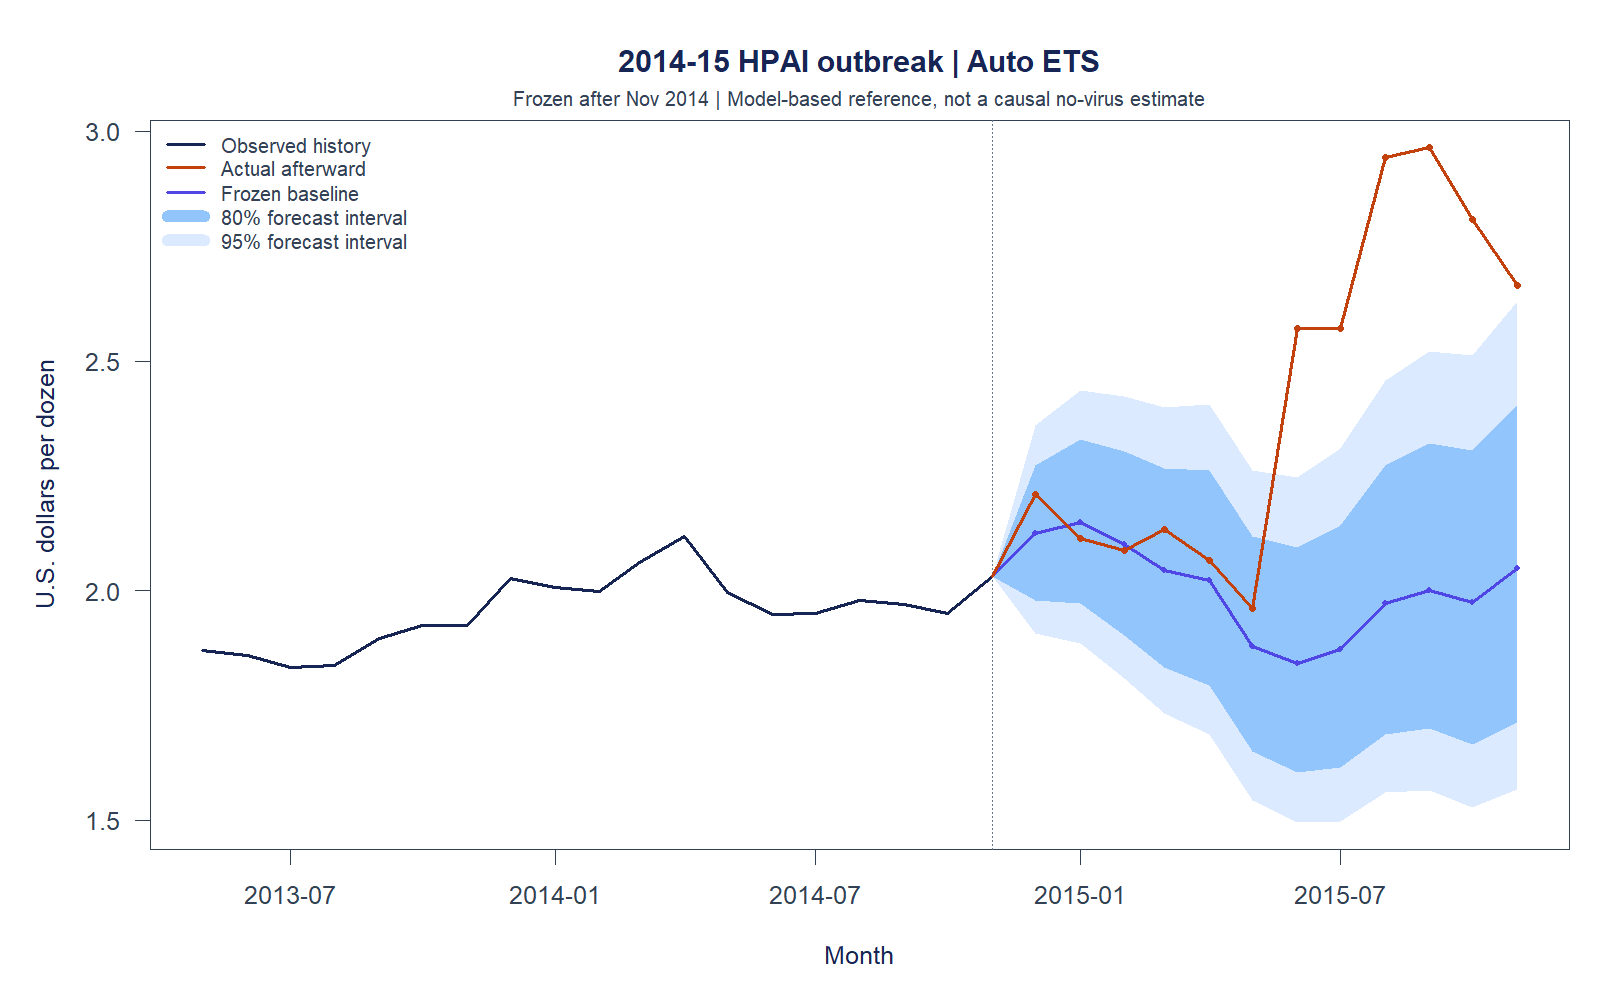

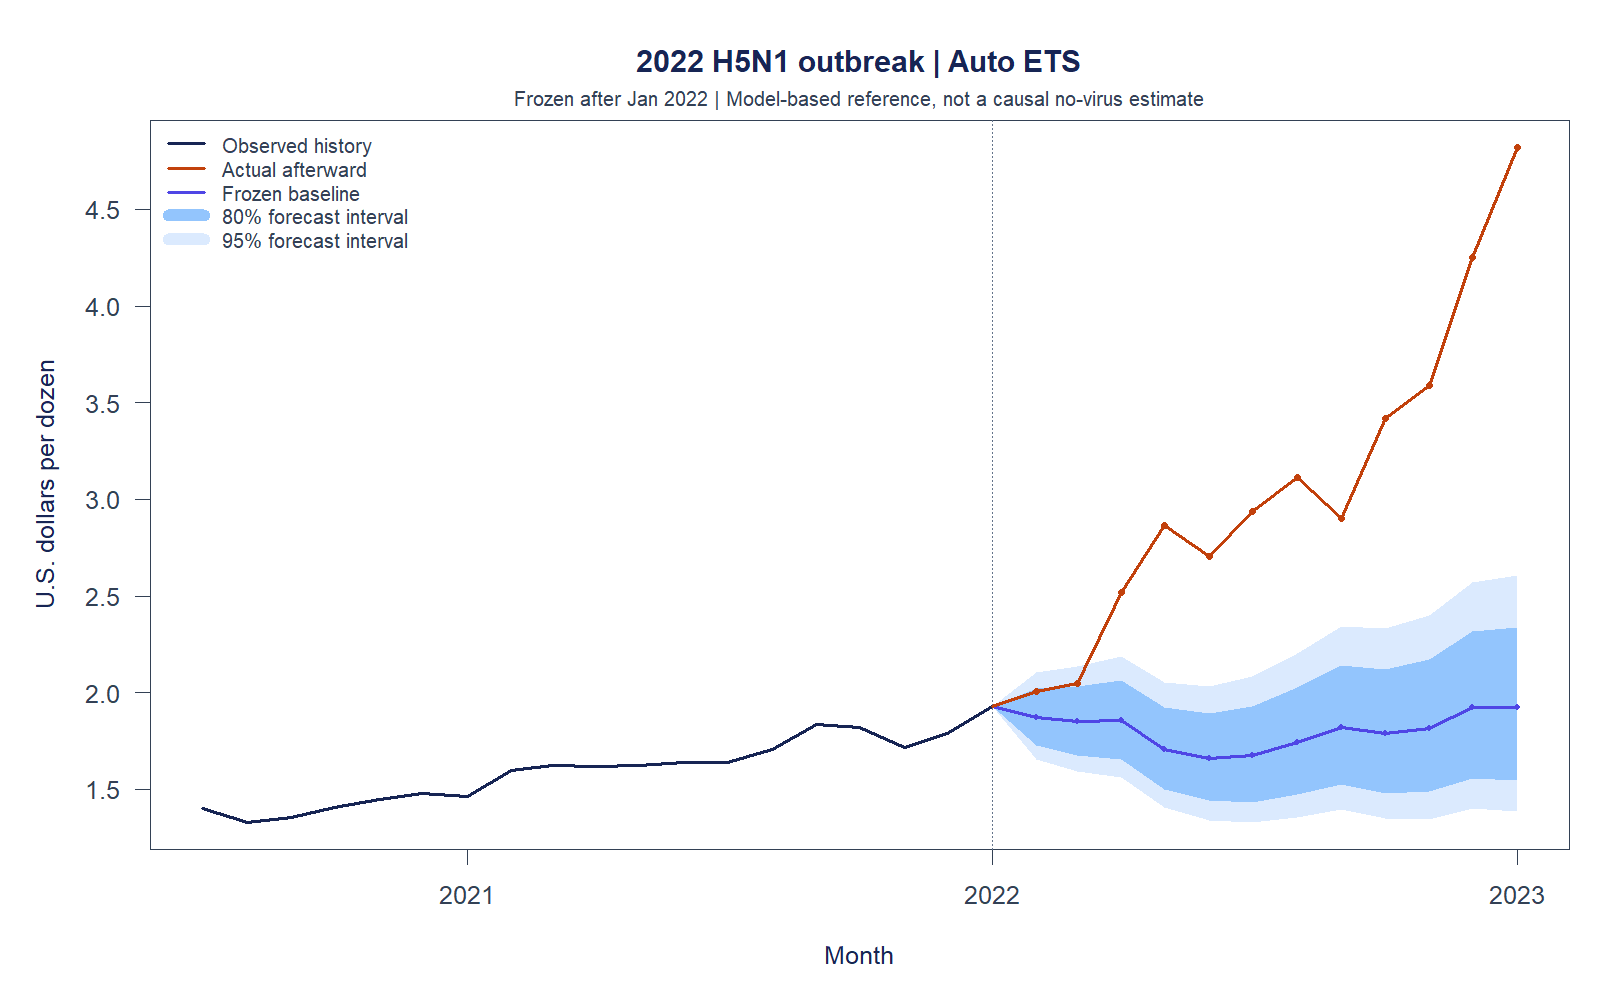

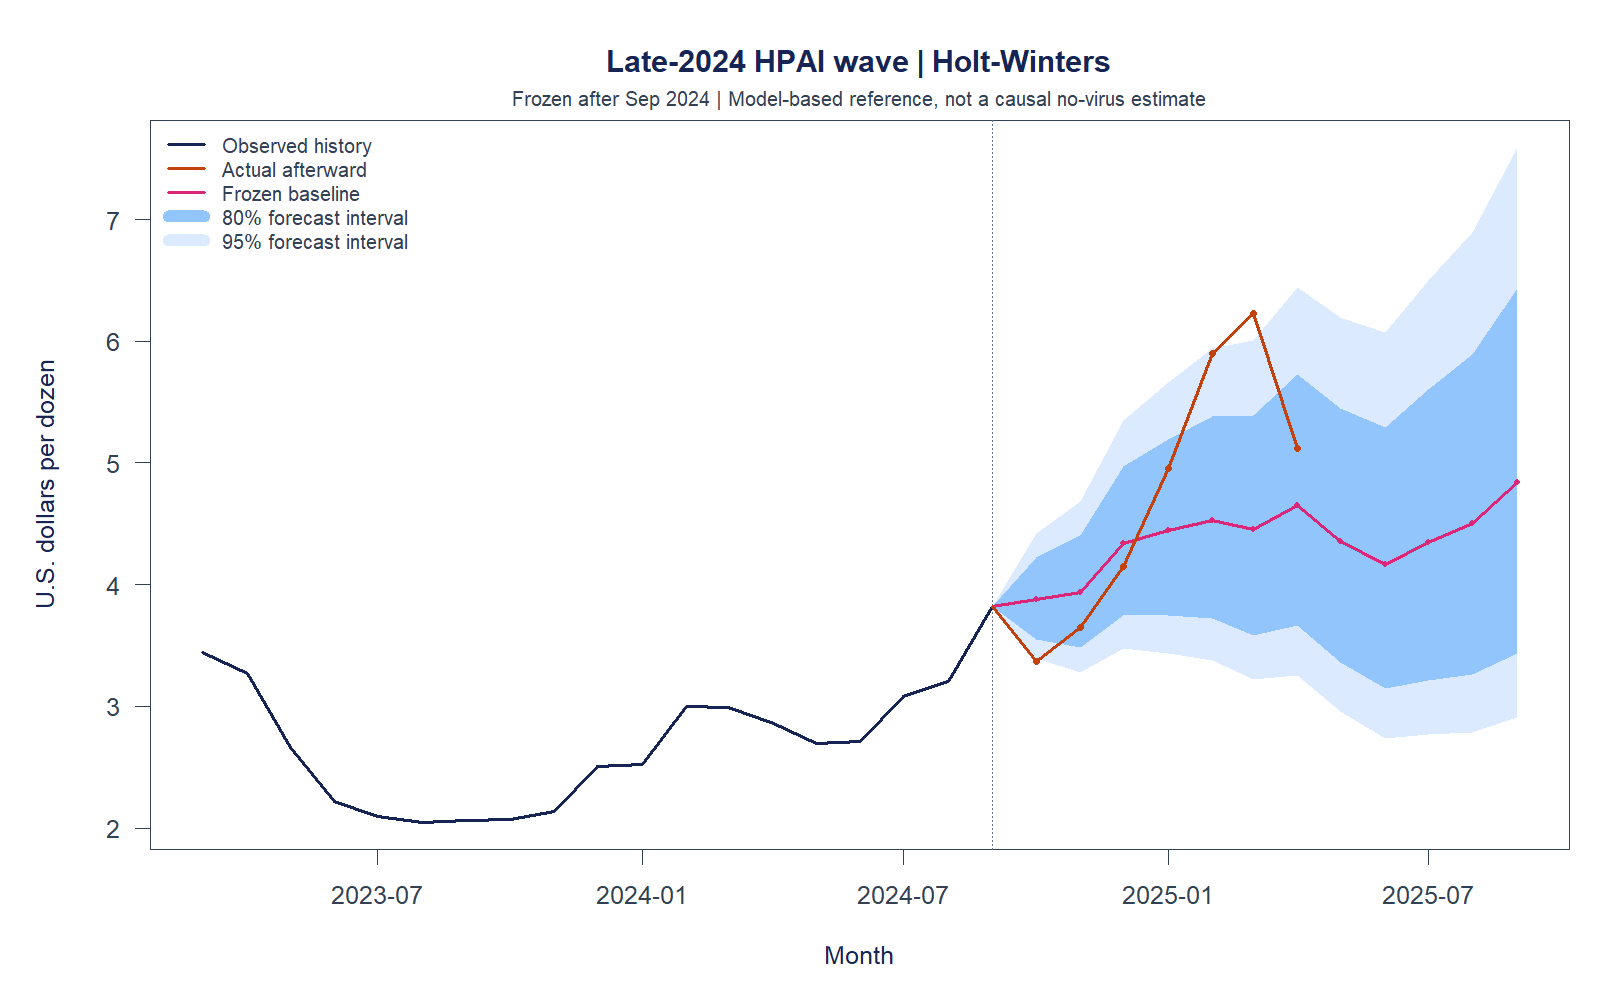

In [3]:
for event in events:
    display(HTML('<h3>' + escape(event['label']) + '</h3>'))
    display(Image(filename=str(OUT / 'figures' / (event['event'] + '_selected.png'))))


## Measure departures from the reference

For month $h$, define $g_h=P_h-\widehat P_h$, and the relative departure as
$100g_h/\widehat P_h$. A positive gap means the actual price exceeded the model
reference. It is **not** a per-dozen cost attributable solely to HPAI.

The peak month is the highest **observed actual price** in the predefined window;
the baseline in that same month is used for the peak gap. Mean gaps average signed
monthly differences; they are not cumulative consumer expenditure effects.
Post-event RMSE measures divergence from actuals, not accuracy for the unobserved
no-outbreak scenario. Unequal observed windows should not be ranked together.


event,model,observed_months,RMSE_first3,mean_gap,peak_date,peak_actual,baseline_at_peak,gap_at_peak,months_above95
hpai_2014_15,Auto ETS,12,0.0538183782382511,0.42211583056091,2015-09-01,2.966,2.00035694567833,0.965643054321672,6
hpai_2022,Auto ETS,12,0.407763208227976,1.29495042602462,2023-01-01,4.823,1.92647593080452,2.89652406919548,10
hpai_late_2024,Holt-Winters,7,0.356545691884856,0.447174223850178,2025-03-01,6.227,4.45445501983226,1.77254498016774,1


hpai_2014_15: peak actual $2.966, baseline $2.000, gap $+0.966 per dozen (+48.3%).
hpai_2022: peak actual $4.823, baseline $1.926, gap $+2.897 per dozen (+150.4%).
hpai_late_2024: peak actual $6.227, baseline $4.454, gap $+1.773 per dozen (+39.8%).


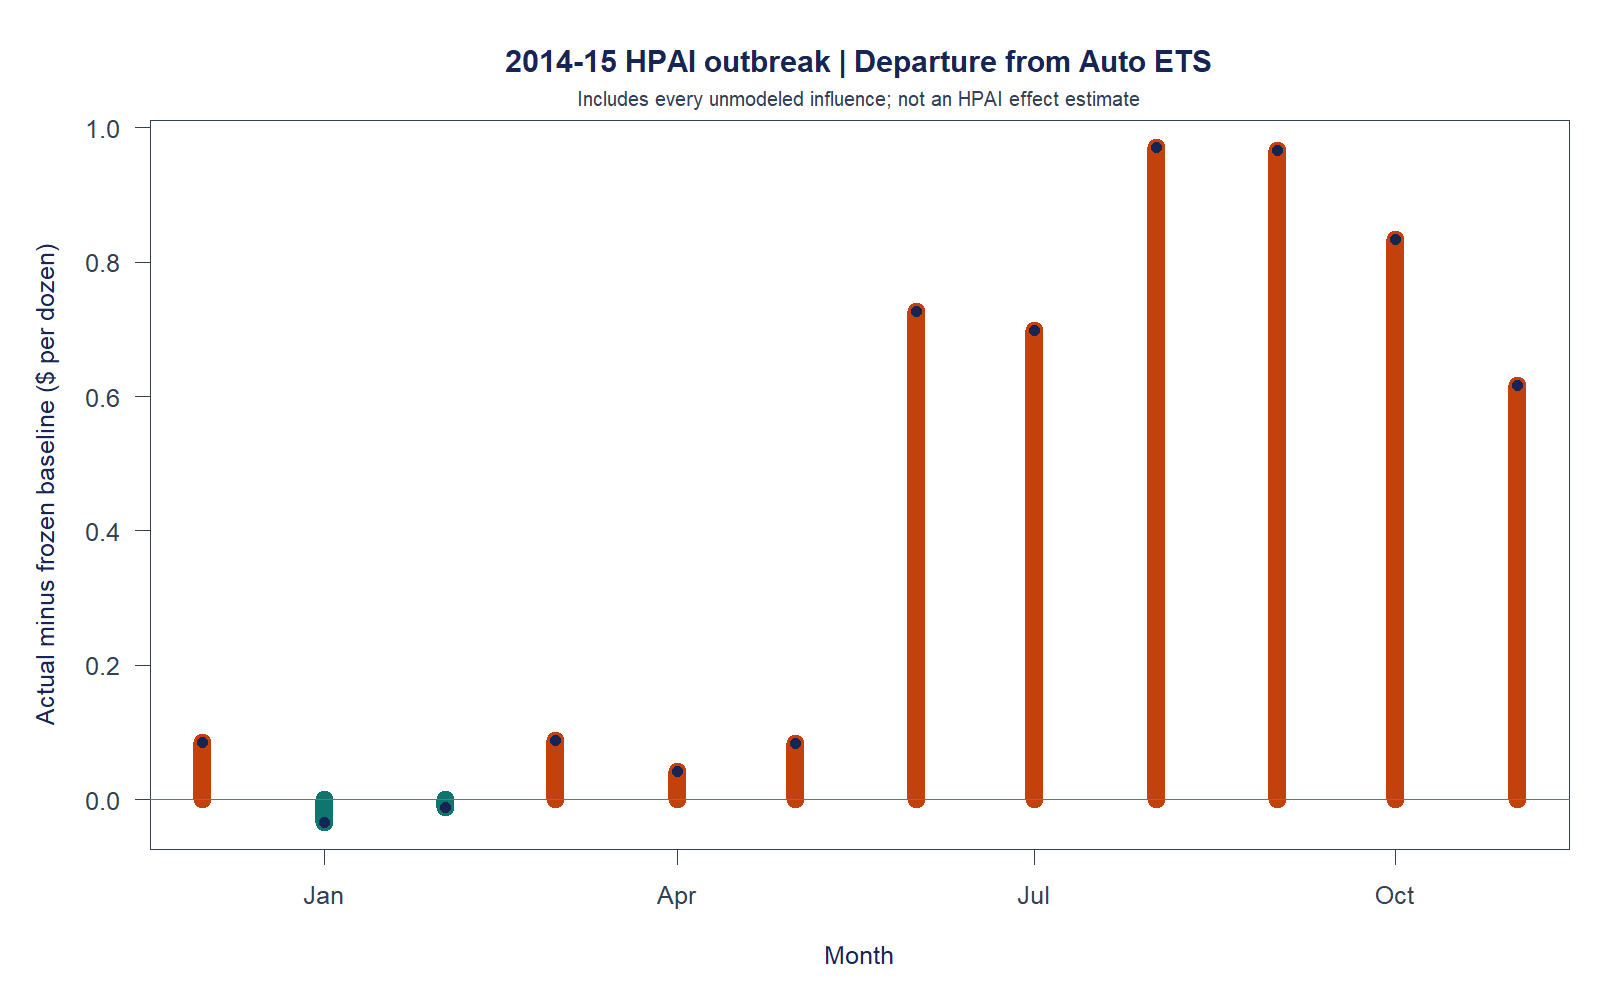

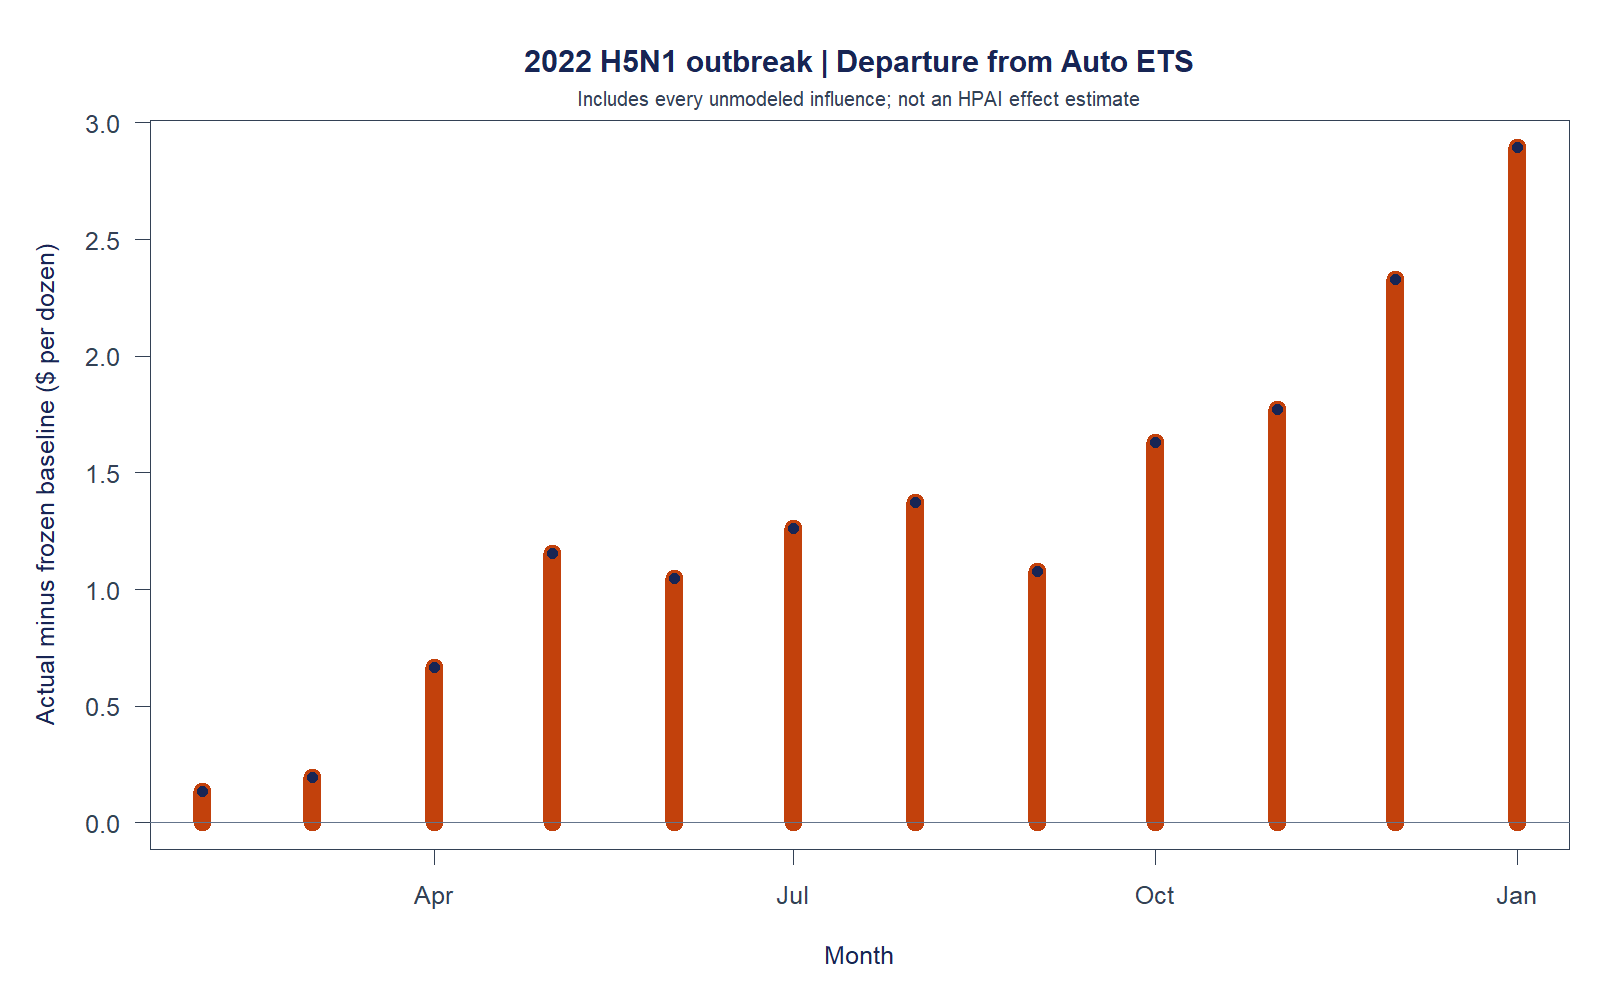

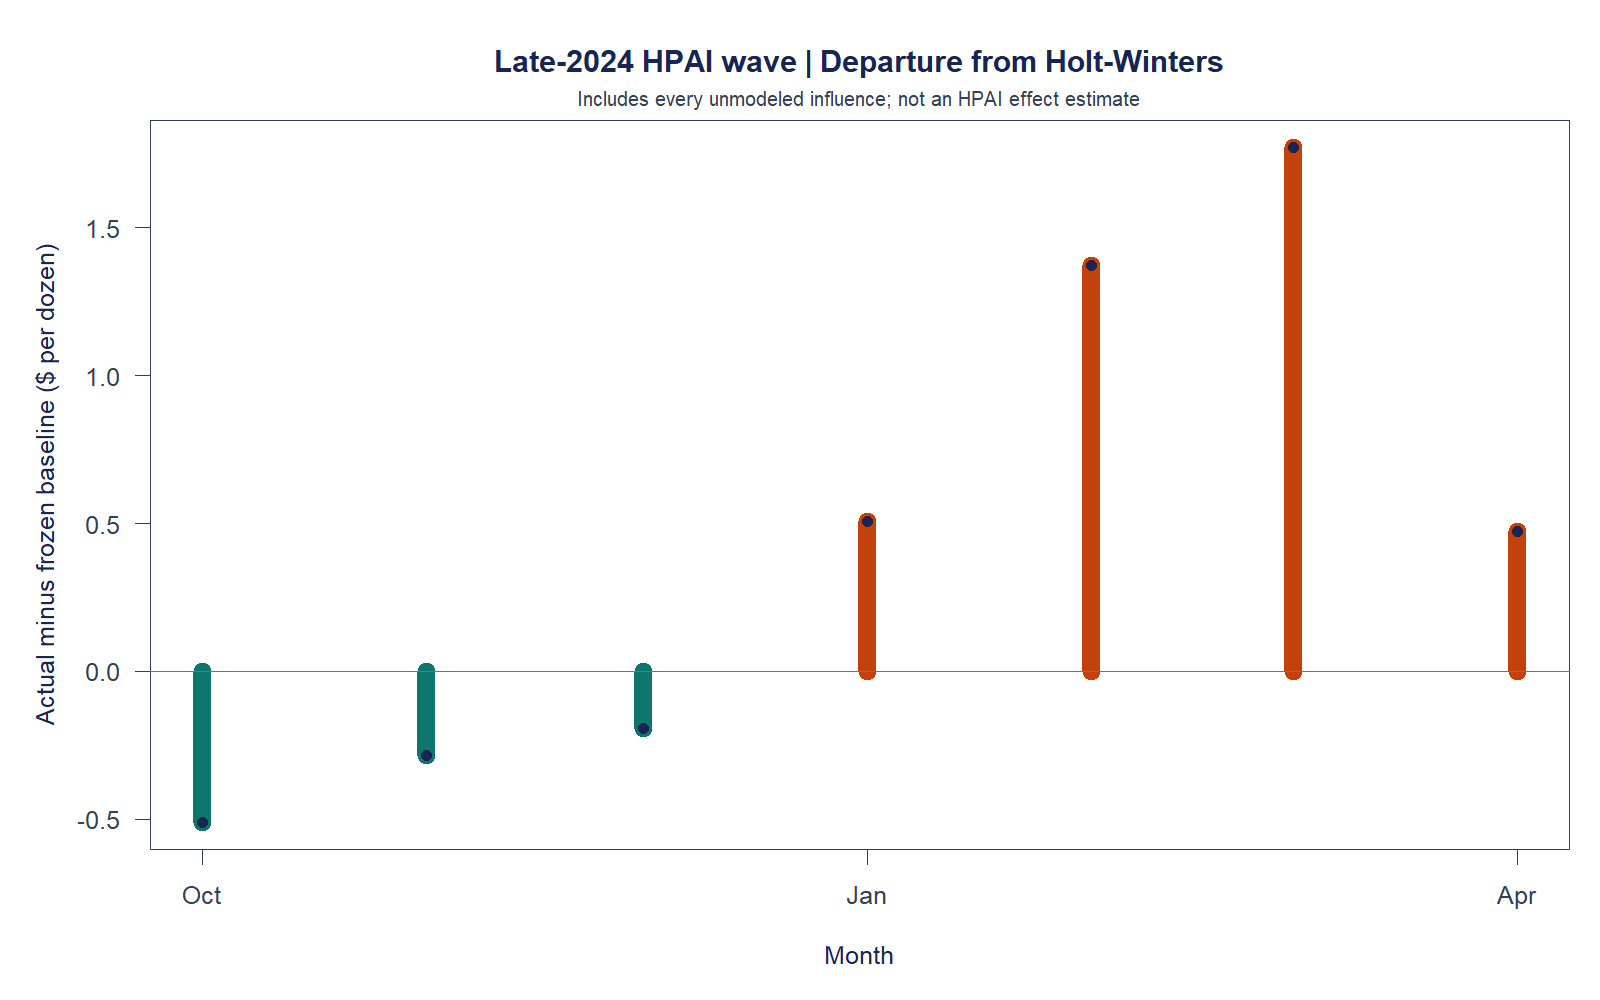

In [4]:
columns = ['event', 'model', 'observed_months', 'RMSE_first3', 'mean_gap',
           'peak_date', 'peak_actual', 'baseline_at_peak', 'gap_at_peak', 'months_above95']
table(selected, columns)
for row in selected:
    print(f"{row['event']}: peak actual ${float(row['peak_actual']):.3f}, "
          f"baseline ${float(row['baseline_at_peak']):.3f}, "
          f"gap ${float(row['gap_at_peak']):+.3f} per dozen "
          f"({float(row['gap_pct_at_peak']):+.1f}%).")
for event in events:
    display(Image(filename=str(OUT / 'figures' / (event['event'] + '_gap.png'))))


## Sensitivity to choosing an earlier starting point

Move the origin back one or three months while keeping the event's target months
unchanged. Reselect using only the **five complete validation blocks** available
at the earlier origin, then refit there. This changes both the training endpoint
and potentially the selected method. The check demonstrates origin/model
sensitivity; it does not distinguish their separate effects or estimate causality.


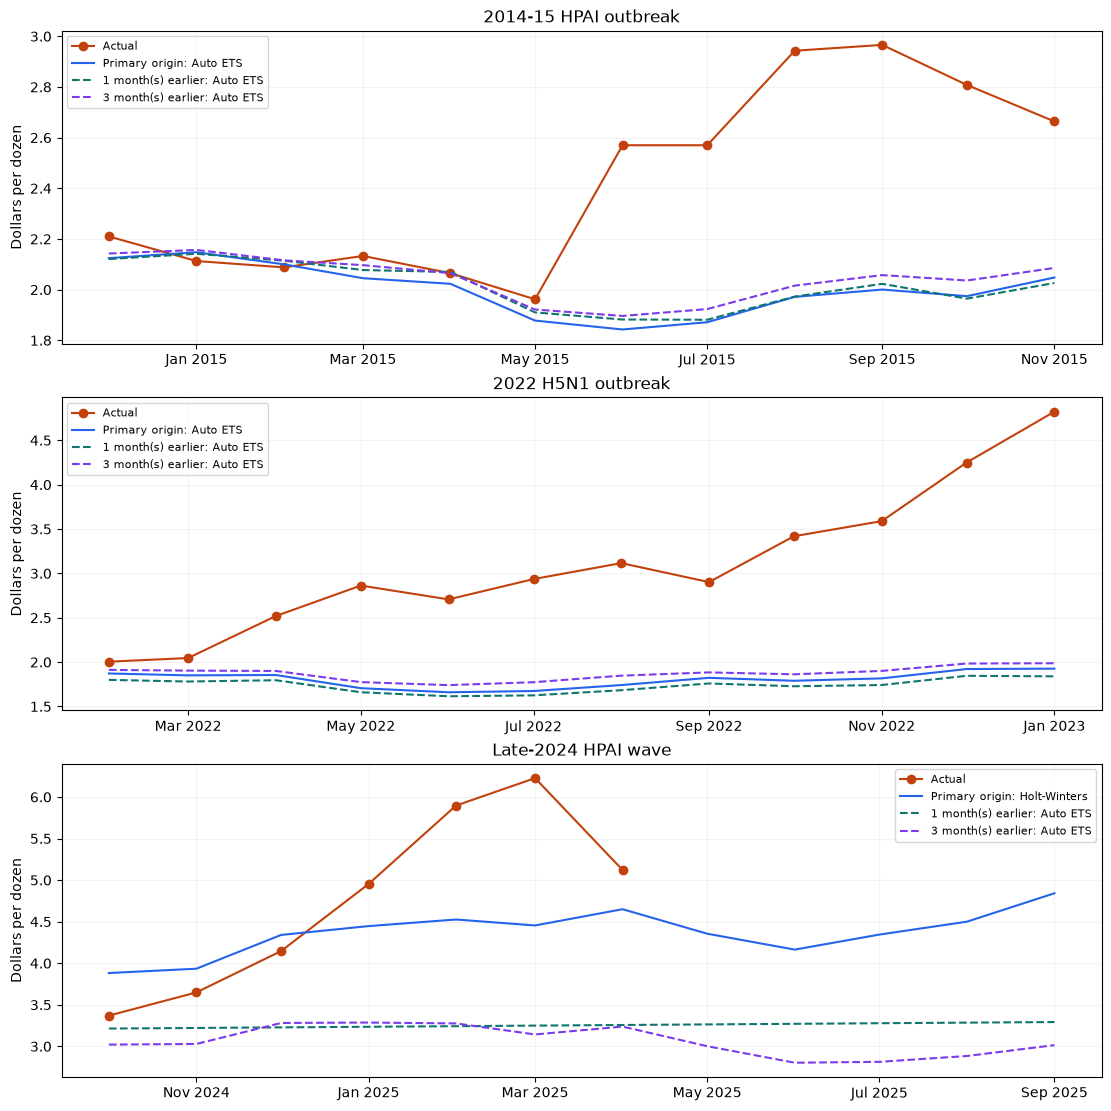

In [5]:
sensitivity = read_csv('origin_sensitivity')
fig, axes = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
for ax, event in zip(axes, events):
    event_id = event['event']
    rows = [r for r in predictions if r['event'] == event_id and r['selected'] == 'TRUE']
    dates = [date.fromisoformat(r['date']) for r in rows]
    actual_rows = [r for r in rows if r['actual'] not in ('NA', '')]
    ax.plot([date.fromisoformat(r['date']) for r in actual_rows],
            [float(r['actual']) for r in actual_rows], color='#c2410c', marker='o', label='Actual')
    ax.plot(dates, [float(r['baseline']) for r in rows], color='#2563eb',
            label='Primary origin: ' + rows[0]['model'])
    for shift, color in [(1, '#0f766e'), (3, '#7c3aed')]:
        earlier = [r for r in sensitivity if r['event'] == event_id and int(r['months_earlier']) == shift]
        ax.plot([date.fromisoformat(r['date']) for r in earlier],
                [float(r['baseline']) for r in earlier], linestyle='--', color=color,
                label=f"{shift} month(s) earlier: {earlier[0]['model']}")
    ax.set(title=event['label'], ylabel='Dollars per dozen')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend(fontsize=8)
    ax.grid(alpha=.15)
fig.savefig(OUT / 'figures' / 'origin_sensitivity.png', dpi=160)
plt.show()


## Check the calendar and recorded outputs

The audits below verify strict training cutoffs, disjoint validation outcomes,
and unavailable future actuals. `frozen_models.rds` retains each fitted model.
`predictions.csv`, `cv_predictions.csv`, `all_model_summary.csv`,
`origin_sensitivity.csv` and `leakage_audit.csv` preserve the full calculations.
The HTML viewer also contains all 27 individual model graphs.

To identify a stronger no-outbreak counterfactual, the next study would need
external predictors or a credible comparison series with a defensible assumption
about how it would evolve without the outbreak. This univariate experiment does
not supply that identification.


In [6]:
audit = read_csv('leakage_audit')
folds = read_csv('cv_folds')
assert len(predictions) == 324 and len(audit) == 27
assert all(r['date'] > r['origin'] for r in predictions)
assert all(r['selection_last_outcome'] <= r['train_end'] < r['forecast_start'] for r in audit)
assert all(r['selection_last_outcome'] <= r['origin'] for r in sensitivity)
for event in events:
    f = sorted([r for r in folds if r['event'] == event['event']], key=lambda r: int(r['fold']))
    assert len(f) == 6 and all(a['validation_end'] < b['validation_start'] for a,b in zip(f,f[1:]))
    assert f[-1]['validation_end'] <= event['origin']
    observed = sum(r['actual'] not in ('NA', '') for r in predictions
                   if r['event'] == event['event'] and r['selected'] == 'TRUE')
    assert observed == (7 if event['event'] == 'hpai_late_2024' else 12)
assert sum(r['actual'] in ('NA', '') for r in predictions) == 45
print('Passed: 324 frozen forecasts, 27 fits, 18 disjoint validation blocks, strict cutoffs, and 45 unavailable actuals across nine methods left unfilled.')
display(HTML('<a href="../results/spike_counterfactual/index.html">Open all graphs and tables</a>'))


Passed: 324 frozen forecasts, 27 fits, 18 disjoint validation blocks, strict cutoffs, and 45 unavailable actuals across nine methods left unfilled.
